#Group Chat/Debate Pattern

In [1]:
!pip install langchain_openai -q
!pip install langchain_chroma -q

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-adk 2.7.1 requires opentelemetry-api<=1.42.1,>=1.39, but you have opentelemetry-api 1.45.2 which is incompatible.
google-adk 2.7.1 requires opentelemetry-sdk<=1.42.1,>=1.39, but you have opentelemetry-sdk 1.45.2 which is incompatible.
tweepy 4.17.0 requires oauthlib<4,>=3.2.0, but you have oauthlib 4.0.1 which is incompatible.


In [7]:
!pip install langchain-google-genai -q

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires google-auth==2.49.0, but you have google-auth 2.63.1 which is incompatible.
google-adk 2.7.1 requires google-genai<3,>=2.12.1, but you have google-genai 3.6.1 which is incompatible.
google-adk 2.7.1 requires opentelemetry-api<=1.42.1,>=1.39, but you have opentelemetry-api 1.45.2 which is incompatible.
google-adk 2.7.1 requires opentelemetry-sdk<=1.42.1,>=1.39, but you have opentelemetry-sdk 1.45.2 which is incompatible.


In [8]:
import os
import sys

from google.colab import userdata

from typing import TypedDict, Annotated, Literal
from langchain_core.messages import HumanMessage, AIMessage, BaseMessage, SystemMessage
from langchain_openai import ChatOpenAI, OpenAIEmbeddings
from langchain_google_genai import ChatGoogleGenerativeAI

from langgraph.graph import START, END, StateGraph
from langgraph.graph.message import add_messages

from pydantic import BaseModel, Field

In [52]:
MODEL_NAME = "gemini-3.8-flash"
MAX_TURNS=8

### Set up Gemini API Key

To use the Gemini API with LangChain, you need a Gemini API Key.
1. Go to [Google AI Studio](https://aistudio.google.com/) and create an API key.
2. In Colab, click the **Secrets** icon (🔑) on the left sidebar, add a new secret named `GOOGLE_API_KEY`, and paste your API key as the value. Toggle "Notebook access" on.

Then, we load the secret and initialize the `ChatGoogleGenerativeAI` model:

In [53]:
# Configure the environment variable for LangChain
if "GOOGLE_API_KEY" not in os.environ:
    os.environ["GOOGLE_API_KEY"] = userdata.get("GOOGLE_API_KEY")

#llm=ChatOpenAI(model_name=MODEL_NAME, temperature=0.5)
# Initialize the Gemini model
llm = ChatGoogleGenerativeAI(
    model=MODEL_NAME,
    temperature=0.5
)

In [54]:
PARTICIPANTS:dict[str,str]={
    "Researcher":(
        "You are the Researcher.  You contribute relevant facts, opinions, and"
        "considerations for the topic.  Be concrete and consice."
    ),
    "Writer":(
        "You are the Writer.  You turn all the ideas into a clear, well-structured draft."
        "Incorporate feedback from the Critic when there is any."
    ),
    "Critic":(
        "You are the Critic.  Review the latest draft or idea, point out gaps, mistakes, or risks, and suggest improvements."
        "If the work is good enough, say so explicitly"
    )
}

In [55]:
class GroupChatState(TypedDict):
  messages:Annotated[list[BaseMessage], add_messages]
  next_speaker:str
  turns:int

In [56]:
def render_transcript(messages:list[BaseMessage]):
  lines=[]

  for m in messages:
    speaker=getattr(m, "name", None) or ("User" if isinstance(m, HumanMessage) else "Assistant")
    lines.append(f"{speaker}:{m.content}")

  return "\n\n".join(lines)

In [57]:
class Route(BaseModel):  #for Literal[] to work needs to be wrapped in a BaseModel class
  next: Literal["Researcher", "Writer", "Critic", "FINISH"]=Field(
      description="Who should need to speak next.  FINISH if task is complete"
  )
  reason:str=Field(description="One short sentence explaining the choice.")


In [58]:
manager_llm=llm.with_structured_output(Route)

In [59]:
MANAGER_PROMPT=f"""You are the manager of a group chat between these participants:
{chr(10).join(f"- {name}: {desc}" for name, desc in PARTICIPANTS.items())}

Given the conversation so, chose which should speak next.

RULES:
- A sensible rule is Researcher -> Writer -> Critic then Writer to revise if needed.
- Do not pick the same participant twice in a row.
- Choose FINISH once the Critic is satisfied with the complete final answer
"""

In [60]:
def manager(state:GroupChatState)->dict:
  turns=state.get("turns",0)

  #safety check
  if turns>MAX_TURNS:
    return {"next_speaker":"FINISH"}

  decision:Route=manager_llm.invoke(
      [
          SystemMessage(content=MANAGER_PROMPT),
          HumanMessage(content=f"Conversation so far: \n\n{render_transcript(state['messages'])}")
      ]
  )

  print(f"\n[manager] -> {decision.next} ({decision.reason})")

  return {"next_speaker":decision.next}

In [61]:
def route_from_manager(state:GroupChatState)->str:
  return END if state["next_speaker"]=="FINISH" else state["next_speaker"]

In [62]:
def make_participant(name: str, persona: str):
  def node(state:GroupChatState)->dict:
    prompt=[
        SystemMessage(content=(
            f"{persona}\n\nYou are in a group chat.  Reply only as {name}, "
            "in at most 150 words.  Do not prefix your reply with your name."
        )),
        HumanMessage(content=f"Conversation so far: \n\n{render_transcript(state['messages'])}")
    ]

    reply=llm.invoke(prompt)
    print(f"\n[{name}]\n{reply.content}")

    return {
        "messages":[AIMessage(content=reply.content, name=name)],
        "turns":state.get("turns",0)+1
    }

  return node  #we return the reference to the node so we can pass it in the graph

In [63]:
def build_graph():
  graph=StateGraph(GroupChatState)

  graph.add_node("manager", manager)

  for name, persona in PARTICIPANTS.items():
    graph.add_node(name, make_participant(name, persona))

  graph.add_edge(START, "manager")

  #manager -> chosen participant or END
  graph.add_conditional_edges(
      "manager",
      route_from_manager,
      {**{name:name for name in PARTICIPANTS}, END: END}  #this will give {'Researcher':'Researcher', 'Writer':'Writer', 'Critic':'Critic', END:END} -> this third param maps from router_for_manager
  )

  #every participant reports back to manager
  for name in PARTICIPANTS:  #loops over the keys only and not (key,value) pairs
    graph.add_edge(name, "manager")

  return graph.compile()


In [66]:
#=====entry point======
if __name__ == "__main__":
  topic=" ".join(sys.argv[1:]) or "Plan a 3-day trip to Matehuala, MX on a modest budget."

  app=build_graph()
  final_state=app.invoke(   #invoke returns the final state dictionary
      {"messages":[HumanMessage(content=topic)], "next_speaker":"", "turns":0},
      config={"recursion_limit":50}  #recursion_limit is a safety rail to only allow 50 nodes transitions
  )

  print("\n" + "=" * 70)
  print("FINAL TRANSCRIPT")
  print("=" * 70)

  print(render_transcript(final_state["messages"]))

GoogleRateLimitError: Error calling model 'gemini-3.8-flash' (RESOURCE_EXHAUSTED): 429 RESOURCE_EXHAUSTED. {'error': {'code': 429, 'message': 'You exceeded your current quota, please check your plan and billing details. For more information on this error, head to: https://aistudio.google.com/docs/rate-limits. To monitor your current usage, head to: https://ai.dev/rate-limit. \n* Quota exceeded for metric: generativelanguage.googleapis.com/generate_content_free_tier_requests, limit: 20, model: gemini-3.8-flash, description: Generate content requests per day limit exceeded on Free Tier. See https://aistudio.google.com/docs/rate-limits.\nPlease retry in 3h56m7.21142241s.', 'status': 'RESOURCE_EXHAUSTED', 'details': [{'@type': 'type.googleapis.com/google.rpc.Help', 'links': [{'description': 'Learn more about Gemini API quotas', 'url': 'https://aistudio.google.com/docs/rate-limits'}]}, {'@type': 'type.googleapis.com/google.rpc.QuotaFailure', 'violations': [{'description': 'Generate content 

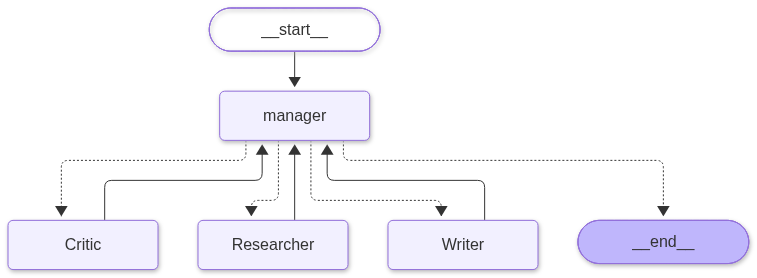

In [28]:
from IPython.display import Image, display

#save png to a file
png_bytes=app.get_graph().draw_mermaid_png()

with open("workflow_graph.png", "wb") as f:
  f.write(png_bytes)

#display the image
display(Image(filename="workflow_graph.png"))